In [2]:
from pathlib import Path
import nibabel as nib
import numpy as np
from numpy.typing import NDArray
from scipy.interpolate import BSpline, make_lsq_spline
from skimage import filters, segmentation
from scipy import ndimage
import matplotlib.pyplot as plt



def trim_initial(data, tr, trim_sec):
    n = max(int(round(trim_sec / tr)), 0)
    return data[..., n:]

def segment_phantom(image):
    edges = filters.sobel(image, mode="wrap")
    labels = np.zeros_like(image, dtype=np.uint8)
    labels[image < np.quantile(image, 0.1)] = 1
    labels[image > np.quantile(image, 0.9)] = 2
    return segmentation.watershed(edges, labels) == 2

def extract_center_slice(data):
    mip = data.max(axis=-1)
    mask_size = [segment_phantom(i).sum() for i in np.moveaxis(mip, -1, 0)]
    center =  np.argmax(mask_size)
    return data[:,:,center,:]

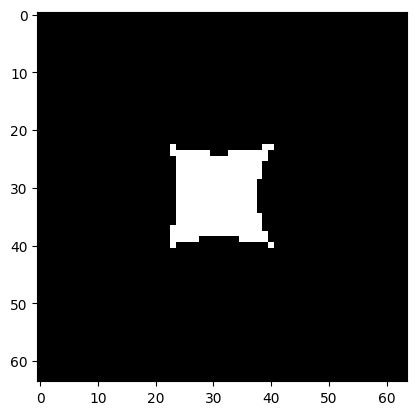

In [11]:
nii = (
    "data/ABCD_QA_fMRI_16.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_13.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_14.nii.gz",
)

img = nib.load(nii[1])
data = img.get_fdata()  # numpy array, shape e.g. (X, Y, Z)
tr = img.header.get_zooms()[3]
dx = img.header.get_zooms()[0]

data = trim_initial(data, tr, 5.0)
center_slice = extract_center_slice(data)
center_slice_mip = center_slice.max(axis=-1)

phantom = segment_phantom(center_slice_mip)

ghost0 = np.roll(phantom, phantom.shape[0]//2, axis=0)
ghost1 = np.roll(phantom, phantom.shape[1]//2, axis=1)

ghost_free = phantom & ~ghost0 & ~ghost1
plt.imshow(ghost_free, "gray")

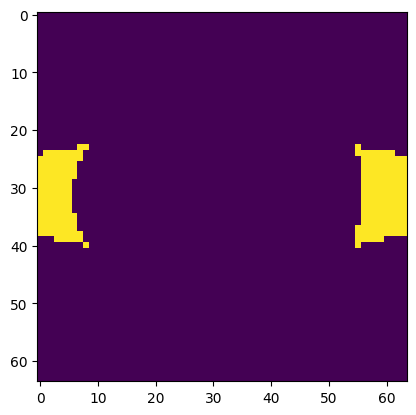

In [14]:
ghost0 = np.roll(ghost_free, phantom.shape[0]//2, axis=0)
ghost1 = np.roll(ghost_free, phantom.shape[1]//2, axis=1)

plt.imshow(ghost1)